![logo](https://raw.githubusercontent.com/matheusvanzan/Time-Series-Examples/refs/heads/master/images/notebook-logo.png)

## **Curso**: Residência em Inteligência Artificial
## **Unidade Curricular**: Séries Temporais
## **Professor**: Matheus Vanzan
---

### Setup

* `numpy` (`np`): cálculos numéricos
* `pandas` (`pd`): tabelas (`DataFrame`) e séries (`Series`)
* `matplotlib.pyplot` (`plt`): gráficos
* `scikit-learn`: a regressão linear (`LinearRegression`), que já conhecemos
* `statsmodels`: os modelos AR (`AutoReg`), MA e ARMA (`ARIMA`), além do `ArmaProcess` para simular

Os imports:

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from statsmodels.tsa.arima_process import ArmaProcess
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.arima.model import ARIMA

Dois ajustes de aparência do `matplotlib`: a grade nos gráficos e o tamanho padrão da figura:

In [ ]:
plt.rcParams['axes.grid'] = True
plt.rcParams['figure.figsize'] = (12, 3.5)

`PATH` é o endereço base dos dados (um repositório no GitHub). Em cada leitura, somamos a ele o caminho do arquivo.

In [ ]:
PATH = 'https://raw.githubusercontent.com/matheusvanzan/Time-Series-Examples/refs/heads/master/'

Vamos simular as séries com **parâmetros conhecidos** e uma **semente fixa** (o mesmo resultado em toda execução). A função `simular_arma` fica aqui no Setup porque a simulação não é o foco da aula. Ela usa o `ArmaProcess` do `statsmodels`, que recebe os coeficientes do AR com o sinal trocado (por isso o `-phi`), e devolve uma série com a média e a escala (tamanho do erro) pedidas:

In [ ]:
def simular_arma(phi, theta, n, semente, media=0, escala=1, indice=None):
    rng = np.random.default_rng(semente)
    ar = np.r_[1, -np.array(phi)]
    ma = np.r_[1, np.array(theta)]
    x = ArmaProcess(ar, ma).generate_sample(nsample=n, distrvs=rng.standard_normal)
    return pd.Series(media + escala * x, index=indice)

## 📌 1 - Defasagem e dispersão

Na Aula 2, as médias móveis e a suavização exponencial só acompanhavam a série, e a previsão seguia uma regra fixa. Hoje vamos entender por que o próximo valor depende do anterior e construir **modelos** que usam essa dependência para prever.

> **Dataset:** o **consumo de energia elétrica de uma fábrica**, uma leitura por hora, em kW. A série é **simulada** (com semente fixa), para conhecermos o mecanismo por trás dela.

### 1.1 - Defasagem (lag)

O consumo tem inércia: máquinas ligadas continuam ligadas, então o consumo de agora fica perto do da hora anterior. O índice de tempo tem uma leitura por hora, e a série vem da função `simular_arma`:

In [ ]:
horas = pd.date_range('2024-03-04 08:00', periods=240, freq='h')
fabrica = simular_arma(phi=[0.85], theta=[], n=240, semente=7, media=120, escala=5, indice=horas)

In [ ]:
fabrica.head()

,0
2024-03-04 08:00:00,120.006151
2024-03-04 09:00:00,121.498956
2024-03-04 10:00:00,119.903423
2024-03-04 11:00:00,115.464951
2024-03-04 12:00:00,113.871854


O dado puro. Já há um valor por hora, então não precisamos de `resample`:

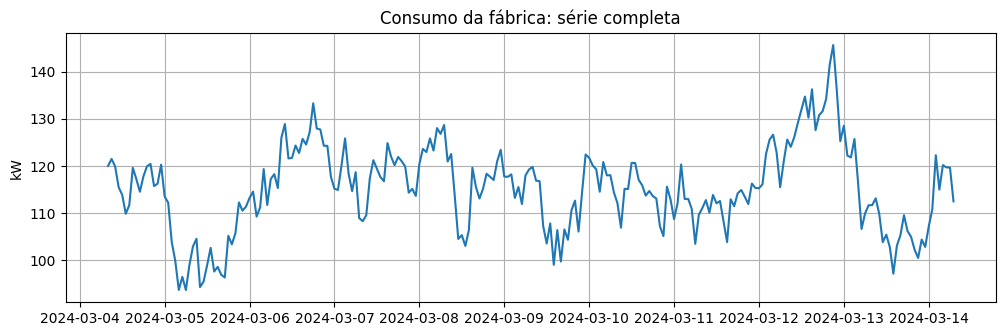

In [ ]:
plt.plot(fabrica.index, fabrica.values)
plt.title('Consumo da fábrica: série completa')
plt.ylabel('kW')
plt.show()

A série **caminha**: depois de um valor alto, vêm valores altos. A pergunta é o quanto o valor de agora se parece com os anteriores, e para isso usamos a defasagem.

A **defasagem** (*lag*) de ordem $k$ desloca a série $k$ períodos para trás: no instante $t$, ela traz o valor $x_{t-k}$. No `pandas`, usamos `.shift(k)`. O argumento é o número de períodos deslocados.

Juntando a série original e os lags 1, 3 e 8 (a coluna `lag 1` traz, em cada linha, a leitura de 1 hora atrás). As primeiras linhas ficam sem valor (`NaN`), porque não existe leitura antes delas:

In [ ]:
lags = pd.DataFrame({
    'x_t': fabrica,
    'lag 1': fabrica.shift(1),
    'lag 3': fabrica.shift(3),
    'lag 8': fabrica.shift(8),
})

In [ ]:
lags.head(10).round(1)

,x_t,lag 1,lag 3,lag 8
2024-03-04 08:00:00,120.0,NaN,NaN,NaN
2024-03-04 09:00:00,121.5,120.0,NaN,NaN
2024-03-04 10:00:00,119.9,121.5,NaN,NaN
2024-03-04 11:00:00,115.5,119.9,120.0,NaN
2024-03-04 12:00:00,113.9,115.5,121.5,NaN
2024-03-04 13:00:00,109.8,113.9,119.9,NaN
2024-03-04 14:00:00,111.7,109.8,115.5,NaN
2024-03-04 15:00:00,119.6,111.7,113.9,NaN
2024-03-04 16:00:00,117.2,119.6,109.8,120.0
2024-03-04 17:00:00,114.5,117.2,111.7,121.5


Cada lag é a mesma série **deslocada para a direita**: o lag 1 atrasa a curva em 1 hora, o lag 3 em 3 horas e o lag 8 em 8 horas. Plotando as primeiras 30 horas, a série e os três lags:

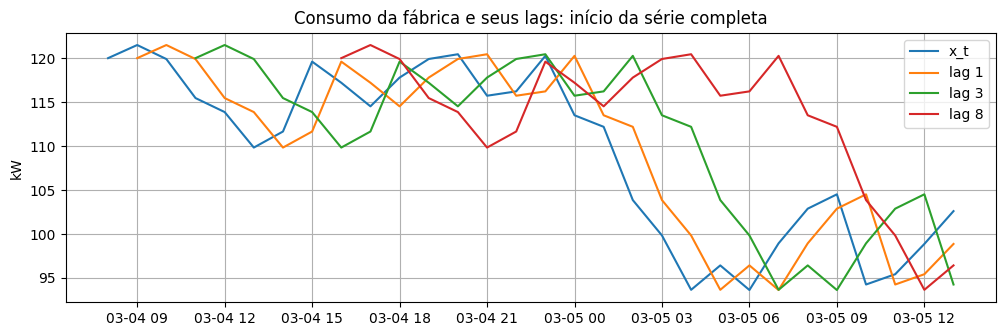

In [ ]:
for coluna in lags.columns:
    plt.plot(lags[coluna].iloc[:30], label=coluna)
plt.title('Consumo da fábrica e seus lags: início da série completa')
plt.ylabel('kW')
plt.legend()
plt.show()

Na linha das 16:00, por exemplo, a coluna `lag 8` traz o valor das 08:00. O que vamos investigar é **o quanto o valor de agora ($x_t$) se parece com o valor defasado ($x_{t-k}$)**.

### 1.2 - Defasagem e dispersão

Cada par ($x_{t-1}$, $x_t$) vira um ponto no gráfico de dispersão: a leitura anterior no eixo $x$ e a leitura de agora no eixo $y$. Os pares ficam sem as linhas com `NaN` (as primeiras, que não têm lag), com `.dropna()`.

In [ ]:
pares = lags[['lag 1', 'x_t']].dropna()

In [ ]:
pares.head()

,lag 1,x_t
2024-03-04 09:00:00,120.006151,121.498956
2024-03-04 10:00:00,121.498956,119.903423
2024-03-04 11:00:00,119.903423,115.464951
2024-03-04 12:00:00,115.464951,113.871854
2024-03-04 13:00:00,113.871854,109.832843


Uma reta resume a relação entre os pares: é a **regressão linear** que já conhecemos, com o lag 1 como entrada (`X`) e $x_t$ como alvo (`y`). Como no `scikit-learn`, primeiro criamos o modelo, `modelo = LinearRegression()`, e depois o ajustamos aos dados com `modelo.fit(X, y)`:

In [ ]:
modelo = LinearRegression()

In [ ]:
modelo.fit(pares[['lag 1']], pares['x_t'])

LinearRegression()

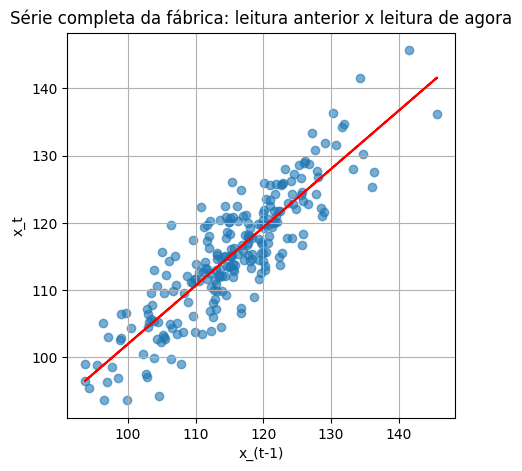

In [ ]:
plt.figure(figsize=(5, 5))
plt.scatter(pares['lag 1'], pares['x_t'], alpha=0.6)
plt.plot(pares['lag 1'], modelo.predict(pares[['lag 1']]), color='red')
plt.xlabel('x_(t-1)')
plt.ylabel('x_t')
plt.title('Série completa da fábrica: leitura anterior x leitura de agora')
plt.show()

A inclinação da reta fica em `modelo.coef_`:

In [ ]:
print('Inclinação da reta:', round(modelo.coef_[0], 2))

Inclinação da reta: 0.87


A nuvem **sobe na diagonal**: valor alto vem depois de valor alto, e a reta vermelha resume isso. A **inclinação** da reta, impressa acima (`modelo.coef_`), diz quanto a leitura de agora sobe, em média, quando a da hora anterior sobe 1 kW. Guarde esse número, porque ele volta no modelo AR.

## 📌 2 - Modelo AR

O AR(1) é a reta do item 1.2:

$$x_t = c + \phi \, x_{t-1} + \varepsilon_t$$

* $c$: a constante, o **intercepto** da reta
* $\phi$: a **inclinação** da reta, o peso do passado (quanto maior $|\phi|$, mais forte a dependência)
* $\varepsilon_t$: o **erro** da regressão

O AR($p$) usa os $p$ valores anteriores: $x_t = c + \phi_1 x_{t-1} + \dots + \phi_p x_{t-p} + \varepsilon_t$. Mais lags dão mais memória, mas também mais parâmetros para estimar.

### 2.1 - Ajuste do AR(1)

Para saber se o modelo prevê bem, reservamos o período final, escondido do modelo: ele é ajustado só com o **treino**, e a previsão é comparada com o que realmente aconteceu no **teste**. Usamos o **consumo da fábrica** (`fabrica`, do item 1.1) e queremos prever as **próximas 20 horas**.

O horizonte é de 20 horas, então o teste tem 20 pontos:

In [ ]:
h = 20
treino = fabrica.iloc[:-h]
teste = fabrica.iloc[-h:]

In [ ]:
print('Pontos de treino:', len(treino), '| pontos de teste:', len(teste))

Pontos de treino: 220 | pontos de teste: 20


Na prática, não escolhemos o $\phi$: o código **estima** o $\phi$ a partir dos dados, como na regressão. O `statsmodels` tem a classe `AutoReg`, própria para o AR($p$). Como no `scikit-learn`, o modelo é criado e depois ajustado com `.fit()`.

> **Por que `AutoReg` e não a `LinearRegression`?** No item 1.2, a regressão linear usou uma coluna de lag que criamos com `.shift(1)`. O `AutoReg` faz a mesma regressão (por mínimos quadrados), mas é feito para séries temporais: cria os lags sozinho a partir de `lags=p`, prevê vários passos à frente reaproveitando as próprias previsões e devolve o intervalo de confiança. Com a `LinearRegression`, teríamos que montar uma coluna para cada lag e repetir a previsão passo a passo, à mão.

Ajustando um AR(1) ao **treino** da fábrica (`treino`), com os argumentos no código:

In [ ]:
modelo_ar1 = AutoReg(
    # série
    treino,

    # lags: p = 1 (o AR usa o valor anterior)
    lags=1,

    # 'c': inclui a constante, o intercepto da reta
    trend='c',
)

In [ ]:
modelo_ar1

In [ ]:
resultado_ar1 = modelo_ar1.fit()

Os parâmetros estimados ficam em `.params`. Cada nome do resultado corresponde a um símbolo da fórmula $x_t = c + \phi \, x_{t-1} + \varepsilon_t$: `const` é o $c$ (o intercepto da reta) e `y.L1` é o $\phi$ (o `L1` quer dizer *lag 1*, o peso do valor de 1 hora atrás). Ligando cada símbolo ao seu valor:

In [ ]:
print('c (const):', round(resultado_ar1.params['const'], 3))
print('phi (y.L1):', round(resultado_ar1.params['y.L1'], 3))

c (const): 15.271
phi (y.L1): 0.868


Para cada hora do treino, o AR(1) usa o valor da hora anterior para estimar o valor de agora (`.fittedvalues`). Comparando com o consumo real nas últimas 60 horas do treino:

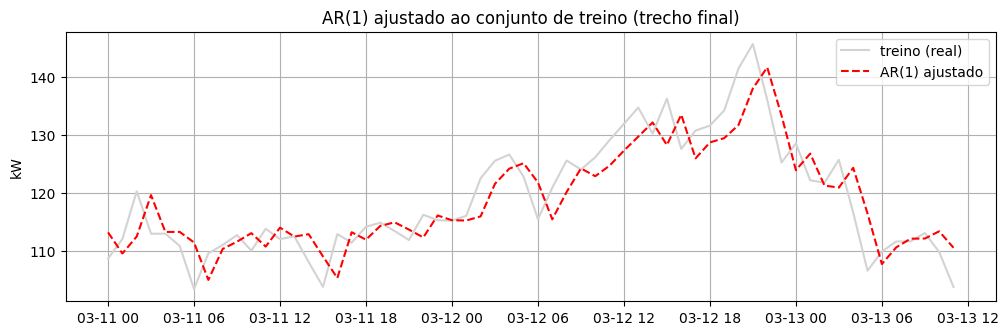

In [ ]:
plt.plot(treino.index[-60:], treino.values[-60:], color='lightgray', label='treino (real)')
plt.plot(resultado_ar1.fittedvalues.index[-60:], resultado_ar1.fittedvalues.values[-60:], color='red', linestyle='--', label='AR(1) ajustado')
plt.title('AR(1) ajustado ao conjunto de treino (trecho final)')
plt.ylabel('kW')
plt.legend()
plt.show()

### 2.2 - Ajuste do AR(p)

No AR($p$), o $p$ é o número de `lags`: basta trocar esse valor. Um AR($p$) tem um $\phi$ para cada lag, `y.L1`, `y.L2`, ..., `y.Lp`. O AR(1) do item anterior é o caso $p$ = 1. Ajustando o AR com $p$ = 1, 2, 3 e 5 ao mesmo treino:

In [ ]:
ordens = [1, 2, 3, 5]
resultados_ar = {p: AutoReg(treino, lags=p, trend='c').fit() for p in ordens}

Cada lista traz o $\phi_1$ (`y.L1`), o $\phi_2$ (`y.L2`), e assim por diante, até o $\phi_p$:

In [ ]:
for p, resultado in resultados_ar.items():
    print('AR(' + str(p) + '):', [round(float(resultado.params['y.L' + str(k)]), 3) for k in range(1, p + 1)])

AR(1): [0.868]
AR(2): [0.811, 0.065]
AR(3): [0.808, 0.022, 0.053]
AR(5): [0.809, 0.024, 0.086, -0.069, 0.033]


Os lags a mais ficam com pesos pequenos: a série da fábrica depende basicamente da hora anterior. A previsão, a seguir, mostra se vale a pena.

### 2.3 - Previsão do AR(1) e do AR(p)

O baseline é o **Naive**, que repete o último valor do treino:

In [ ]:
naive = pd.Series(treino.iloc[-1], index=teste.index)

A previsão para as 20 horas seguintes vem de `.get_prediction`, que devolve a previsão e o intervalo de confiança. Os argumentos `start` e `end` marcam o primeiro e o último período previsto:

In [ ]:
previsao = resultado_ar1.get_prediction(
    # primeiro período previsto: logo depois do treino
    start=len(treino),

    # último período previsto: start + h - 1
    end=len(treino) + h - 1,
)
prev_fabrica = previsao.predicted_mean

In [ ]:
prev_fabrica.head()

,predicted_mean
2024-03-13 12:00:00,105.326245
2024-03-13 13:00:00,106.650232
2024-03-13 14:00:00,107.798905
2024-03-13 15:00:00,108.795478
2024-03-13 16:00:00,109.660091


O intervalo de confiança da previsão, em `.conf_int()`. O nível padrão é 95% (`alpha=0.05`): a faixa em que o valor real deve cair com 95% de confiança, se o erro for normal:

In [ ]:
intervalo = previsao.conf_int(alpha=0.05)

In [ ]:
intervalo.head()

,lower,upper
2024-03-13 12:00:00,96.511498,114.140993
2024-03-13 13:00:00,94.980405,118.320059
2024-03-13 14:00:00,94.374787,121.223023
2024-03-13 15:00:00,94.189224,123.401732
2024-03-13 16:00:00,94.223638,125.096544


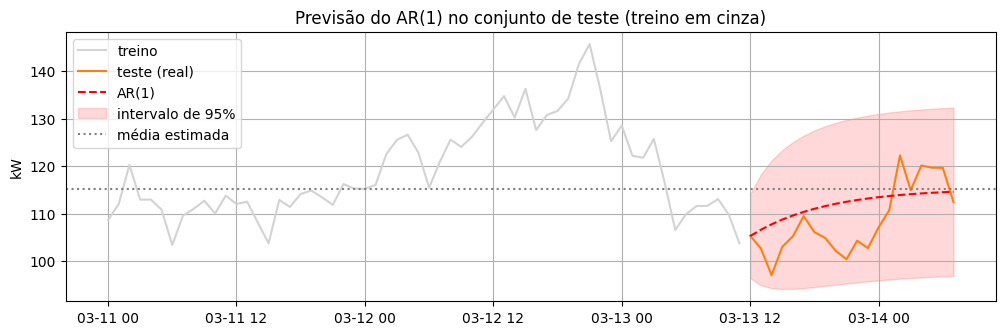

In [ ]:
plt.plot(treino.index[-60:], treino.values[-60:], color='lightgray', label='treino')
plt.plot(teste.index, teste.values, color='tab:orange', label='teste (real)')
plt.plot(prev_fabrica.index, prev_fabrica.values, color='red', linestyle='--', label='AR(1)')
plt.fill_between(intervalo.index, intervalo.iloc[:, 0], intervalo.iloc[:, 1], color='red', alpha=0.15, label='intervalo de 95%')
plt.axhline(resultado_ar1.params['const'] / (1 - resultado_ar1.params['y.L1']), color='gray', linestyle=':', label='média estimada')
plt.title('Previsão do AR(1) no conjunto de teste (treino em cinza)')
plt.ylabel('kW')
plt.legend()
plt.show()

* A previsão do AR(1) **volta à média**: o efeito do último valor se dilui a cada passo (a linha cinza pontilhada é a média estimada pelo modelo)
* A **incerteza cresce** com o horizonte: a faixa se abre

Comparando o AR(1), o AR($p$) (com $p$ = 2, 3 e 5) e o Naive nas 20 horas do teste, pelo erro médio absoluto (MAE) e pela raiz do erro quadrático médio (RMSE), como na Aula 2:

In [ ]:
previsoes_ar = pd.DataFrame({
    'AR(1)': prev_fabrica,
    'AR(2)': resultados_ar[2].forecast(steps=h),
    'AR(3)': resultados_ar[3].forecast(steps=h),
    'AR(5)': resultados_ar[5].forecast(steps=h),
    'Naive': naive,
})

As previsões de cada ordem, contra o consumo real do teste:

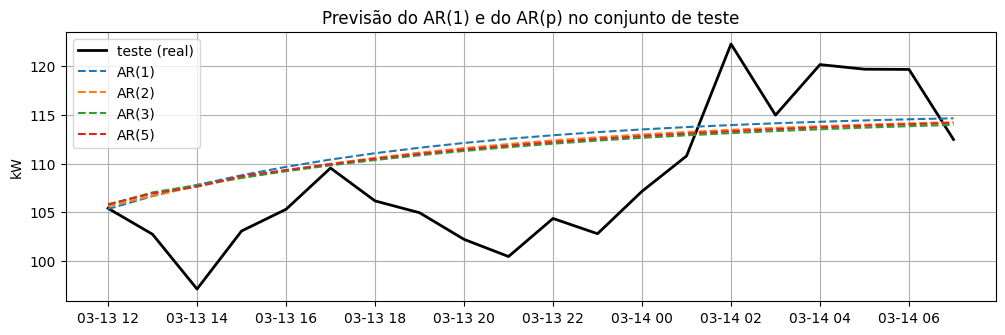

In [ ]:
plt.plot(teste.index, teste.values, color='black', linewidth=2, label='teste (real)')
for coluna in ['AR(1)', 'AR(2)', 'AR(3)', 'AR(5)']:
    plt.plot(previsoes_ar[coluna], linestyle='--', label=coluna)
plt.title('Previsão do AR(1) e do AR(p) no conjunto de teste')
plt.ylabel('kW')
plt.legend()
plt.show()

In [ ]:
erros_prev_ar = previsoes_ar.rsub(teste, axis=0)

In [ ]:
tabela_ar = pd.DataFrame({
    'MAE (kW)': erros_prev_ar.abs().mean(),
    'RMSE (kW)': np.sqrt((erros_prev_ar ** 2).mean()),
})

In [ ]:
for nome, linha in tabela_ar.sort_values('MAE (kW)').iterrows():
    print(nome, '| MAE (kW):', round(linha['MAE (kW)'], 2), '| RMSE (kW):', round(linha['RMSE (kW)'], 2))

AR(3) | MAE (kW): 5.55 | RMSE (kW): 6.43
AR(5) | MAE (kW): 5.59 | RMSE (kW): 6.46
AR(2) | MAE (kW): 5.59 | RMSE (kW): 6.49
AR(1) | MAE (kW): 5.76 | RMSE (kW): 6.67
Naive | MAE (kW): 6.21 | RMSE (kW): 8.6


In [ ]:
melhor_ar = tabela_ar['MAE (kW)'].drop('Naive').idxmin()
ganho = 1 - tabela_ar.loc[melhor_ar, 'MAE (kW)'] / tabela_ar.loc['AR(1)', 'MAE (kW)']
print('Melhor AR:', melhor_ar, '| ganho sobre o AR(1):', round(100 * ganho, 1), '%')

Melhor AR: AR(3) | ganho sobre o AR(1): 3.6 %


**Conclusão:** todos os AR erram menos que o Naive nas 20 horas de teste. Neste período, as ordens maiores melhoram pouco e custam mais parâmetros.

## 📌 3 - Modelo MA

O **MA** (*moving average*) combina **erros** de previsão:

$$x_t = \mu + \theta \, \varepsilon_{t-1} + \varepsilon_t$$

* $\mu$: a média global da série (no MA(0), a previsão é só $\mu$)
* $\theta$: o peso do erro anterior (com sinal de mais, como no `statsmodels`)
* $\varepsilon_{t-1}$: o erro de previsão do período anterior, calculado em sequência: $\varepsilon_t = x_t - \mu - \theta \, \varepsilon_{t-1}$
* $\varepsilon_t$: o erro de agora, que só é conhecido depois que o valor acontece

A previsão do MA(1) é $\hat{x}_t = \mu + \theta \, \varepsilon_{t-1}$. O MA($q$) soma os $q$ erros anteriores, $x_t = \mu + \theta_1 \varepsilon_{t-1} + \dots + \theta_q \varepsilon_{t-q} + \varepsilon_t$, e depois de $q$ períodos o efeito de um erro acaba.

### 3.1 - Ajuste do MA(1)

O `statsmodels` calcula os erros em sequência e estima o $\mu$ e o $\theta$ a partir dos dados. Ele não tem uma classe só para o MA: usamos a `ARIMA`, que na Aula 4 ganhará a diferenciação. O argumento `order=(p, d, q)` tem o **0 no meio** (sem diferenciação), e o MA($q$) é `order=(0, 0, q)`. Atenção: na `ARIMA`, o `const` é a **média** da série, enquanto no `AutoReg` ele é o intercepto $c$.

Ajustando um MA(1) ao **treino** da fábrica, com `order=(0, 0, 1)`:

In [ ]:
# Parâmetros do modelo ARIMA(p, d, q)
p = 0  # AutoRegressivo (AR): quantidade de valores anteriores utilizados
d = 0  # Diferenciação (I): utilizada no ARIMA (assunto da próxima aula)
q = 1  # Média Móvel (MA): quantidade de erros anteriores utilizados

# Com (0, 0, 1), temos um modelo MA(1)
ajuste_ma = ARIMA(treino, order=(p, d, q), trend='c').fit()

Cada nome do resultado corresponde a um símbolo da fórmula $x_t = \mu + \theta \, \varepsilon_{t-1} + \varepsilon_t$: `const` é o $\mu$ (a média) e `ma.L1` é o $\theta$ (o `L1` quer dizer *lag 1*, o peso do erro de 1 hora atrás). Ligando cada símbolo ao seu valor:

In [ ]:
print('mi (const):', round(ajuste_ma.params['const'], 3))
print('theta (ma.L1):', round(ajuste_ma.params['ma.L1'], 3))

mi (const): 115.809
theta (ma.L1): 0.712


In [ ]:
ajuste_ma.fittedvalues.head()

,0
2024-03-04 08:00:00,115.808555
2024-03-04 09:00:00,117.791486
2024-03-04 10:00:00,118.063066
2024-03-04 11:00:00,117.028332
2024-03-04 12:00:00,114.733378


O MA(1) ajustado, para cada hora do treino, contra o consumo real nas últimas 60 horas:

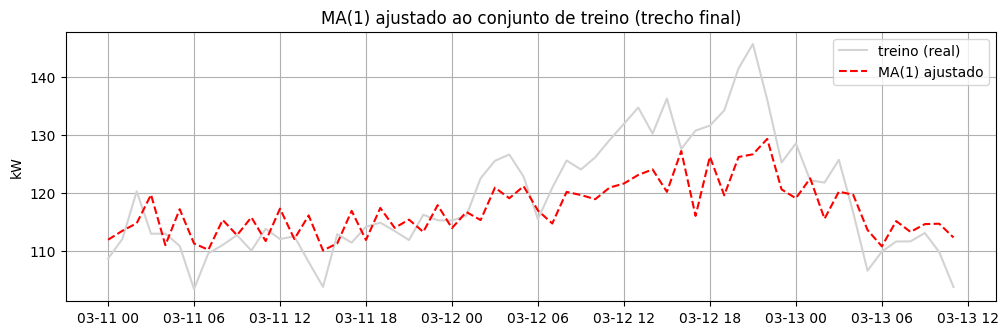

In [ ]:
plt.plot(treino.index[-60:], treino.values[-60:], color='lightgray', label='treino (real)')
plt.plot(ajuste_ma.fittedvalues.index[-60:], ajuste_ma.fittedvalues.values[-60:], color='red', linestyle='--', label='MA(1) ajustado')
plt.title('MA(1) ajustado ao conjunto de treino (trecho final)')
plt.ylabel('kW')
plt.legend()
plt.show()

### 3.2 - Ajuste do MA(q)

No MA($q$), o $q$ é o número de erros anteriores: na `ARIMA`, é o último valor de `order=(0, 0, q)`. Um MA($q$) tem um $\theta$ para cada erro anterior, `ma.L1`, `ma.L2`, ..., `ma.Lq`. Ajustando o MA com $q$ = 2, 3 e 5 ao mesmo treino:

In [ ]:
ordens_ma = [2, 3, 5]
resultados_ma = {q: ARIMA(treino, order=(0, 0, q), trend='c').fit() for q in ordens_ma}

Cada lista traz o $\theta_1$ (`ma.L1`), o $\theta_2$ (`ma.L2`), e assim por diante, até o $\theta_q$:

In [ ]:
for q, resultado in resultados_ma.items():
    print('MA(' + str(q) + '):', [round(float(resultado.params['ma.L' + str(k)]), 3) for k in range(1, q + 1)])

MA(2): [0.89, 0.431]
MA(3): [0.85, 0.66, 0.43]
MA(5): [0.875, 0.707, 0.603, 0.396, 0.164]


### 3.3 - Previsão do MA(1) e do MA(q)

A previsão do MA(1) usa o erro anterior: $\hat{x}_{t+1} = \mu + \theta \, \varepsilon_t$. Depois de $q$ passos, o erro já não pesa e a previsão é a média $\mu$. Com o MA(1) ajustado ao treino, prevemos as mesmas 20 horas do teste. O argumento `steps` é o horizonte:

In [ ]:
previsao_ma = ajuste_ma.get_forecast(
    # horizonte: quantos passos à frente prever
    steps=h,
)
prev_ma = previsao_ma.predicted_mean

In [ ]:
prev_ma.head()

,predicted_mean
2024-03-13 12:00:00,109.730339
2024-03-13 13:00:00,115.808555
2024-03-13 14:00:00,115.808555
2024-03-13 15:00:00,115.808555
2024-03-13 16:00:00,115.808555


Só o primeiro passo usa o último erro. Do segundo em diante, a previsão é a média estimada (`const`):

In [ ]:
print('Média estimada (const):', round(ajuste_ma.params['const'], 3))

Média estimada (const): 115.809


O intervalo de confiança de 95% da previsão:

In [ ]:
intervalo_ma = previsao_ma.conf_int(alpha=0.05)

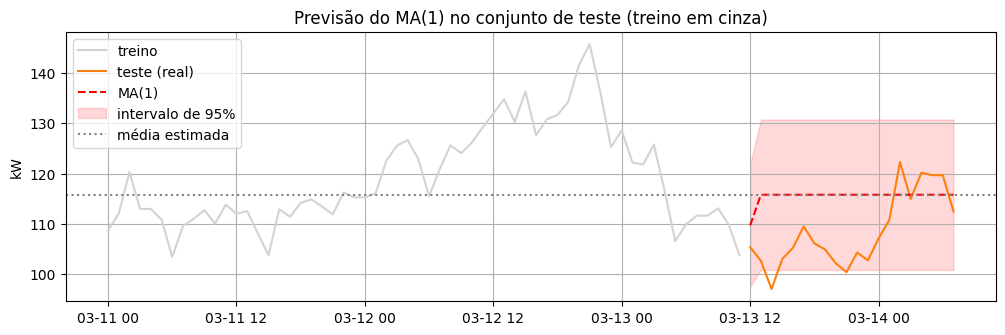

In [ ]:
plt.plot(treino.index[-60:], treino.values[-60:], color='lightgray', label='treino')
plt.plot(teste.index, teste.values, color='tab:orange', label='teste (real)')
plt.plot(prev_ma.index, prev_ma.values, color='red', linestyle='--', label='MA(1)')
plt.fill_between(intervalo_ma.index, intervalo_ma.iloc[:, 0], intervalo_ma.iloc[:, 1], color='red', alpha=0.15, label='intervalo de 95%')
plt.axhline(ajuste_ma.params['const'], color='gray', linestyle=':', label='média estimada')
plt.title('Previsão do MA(1) no conjunto de teste (treino em cinza)')
plt.ylabel('kW')
plt.legend()
plt.show()

Comparando o MA(1), o MA($q$) (com $q$ = 2, 3 e 5) e o Naive nas 20 horas do teste, pelo erro médio absoluto (MAE) e pela raiz do erro quadrático médio (RMSE):

In [ ]:
previsoes_ma_q = pd.DataFrame({
    'MA(1)': prev_ma,
    'MA(2)': resultados_ma[2].forecast(steps=h),
    'MA(3)': resultados_ma[3].forecast(steps=h),
    'MA(5)': resultados_ma[5].forecast(steps=h),
    'Naive': naive,
})

As previsões de cada ordem, contra o consumo real do teste:

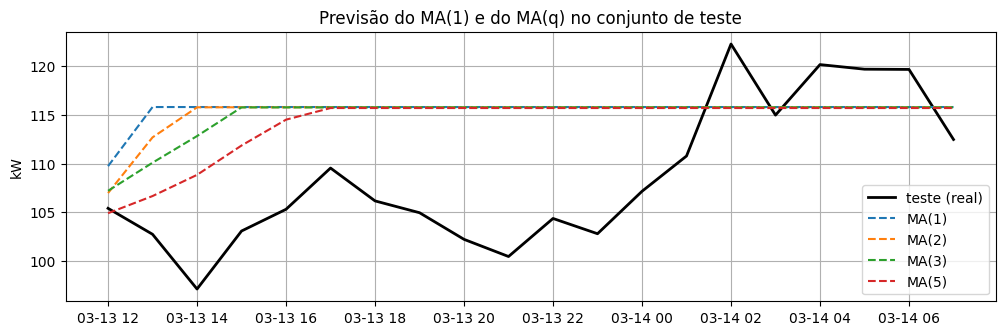

In [ ]:
plt.plot(teste.index, teste.values, color='black', linewidth=2, label='teste (real)')
for coluna in ['MA(1)', 'MA(2)', 'MA(3)', 'MA(5)']:
    plt.plot(previsoes_ma_q[coluna], linestyle='--', label=coluna)
plt.title('Previsão do MA(1) e do MA(q) no conjunto de teste')
plt.ylabel('kW')
plt.legend()
plt.show()

In [ ]:
erros_prev_ma = previsoes_ma_q.rsub(teste, axis=0)

In [ ]:
tabela_ma = pd.DataFrame({
    'MAE (kW)': erros_prev_ma.abs().mean(),
    'RMSE (kW)': np.sqrt((erros_prev_ma ** 2).mean()),
})

In [ ]:
for nome, linha in tabela_ma.sort_values('MAE (kW)').iterrows():
    print(nome, '| MAE (kW):', round(linha['MAE (kW)'], 2), '| RMSE (kW):', round(linha['RMSE (kW)'], 2))

Naive | MAE (kW): 6.21 | RMSE (kW): 8.6
MA(5) | MAE (kW): 7.51 | RMSE (kW): 8.59
MA(3) | MAE (kW): 8.22 | RMSE (kW): 9.34
MA(2) | MAE (kW): 8.49 | RMSE (kW): 9.73
MA(1) | MAE (kW): 8.8 | RMSE (kW): 9.97


**Conclusão:** o MA melhora conforme o $q$ aumenta, porque mais erros anteriores imitam a memória longa da série, mas mesmo o MA(5) não vence o Naive no MAE. O AR(1) faz o trabalho com um parâmetro só: o MA sozinho não é o modelo certo para esta série, cujo consumo de agora depende do valor da hora anterior.

## 🎯 Momento de praticar

Um **sensor de pressão** de uma linha de produção registra uma leitura por minuto (em bar). Ajuste os modelos AR e MA a essa série, preveja os próximos 20 minutos com cada um e compare os dois com o Naive. Os passos:

1. Crie a série do sensor e **plote** (ela é simulada, como o consumo da fábrica)
2. Reserve os **últimos 20 minutos** para teste
3. Ajuste **AR(1) e MA(1)** ao treino
4. **Preveja** os 20 minutos com cada modelo e calcule o **MAE** de cada um e do **Naive** (o último valor do treino)
5. Plote o teste com as duas previsões

> **Dica:** o AR(1) usa `AutoReg(treino, lags=1)`, e o MA(1) usa `ARIMA(treino, order=(0, 0, 1))`. O `.forecast(steps=h)` devolve a previsão dos próximos $h$ períodos, e o MAE é `(teste - previsao).abs().mean()`.

Para criar a série, use:

```python
minutos_s = pd.date_range('2024-05-06 08:00', periods=300, freq='min')
sensor = simular_arma(phi=[0.7], theta=[0.4], n=300, semente=72, media=50, escala=2, indice=minutos_s)
```

**Passo 1:** crie a série do sensor e plote.

In [ ]:
minutos_s = pd.date_range('2024-05-06 08:00', periods=300, freq='min')
sensor = simular_arma(phi=[0.7], theta=[0.4], n=300, semente=72, media=50, escala=2, indice=minutos_s)

In [ ]:
sensor.head()

,0
2024-05-06 08:00:00,47.993348
2024-05-06 08:01:00,47.736087
2024-05-06 08:02:00,49.564010
2024-05-06 08:03:00,46.789195
2024-05-06 08:04:00,43.608438


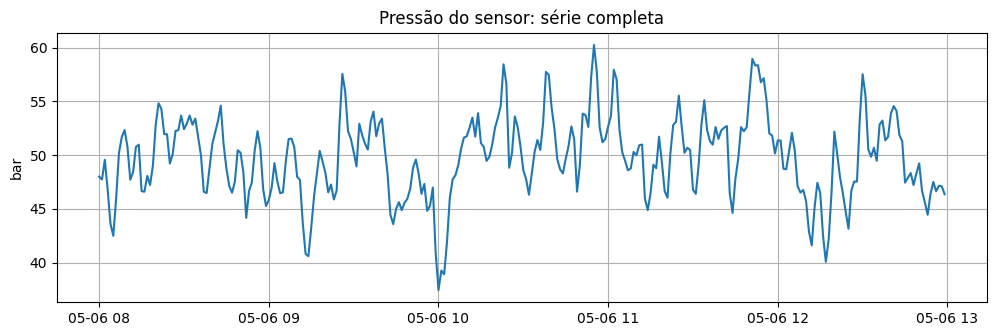

In [ ]:
plt.plot(sensor.index, sensor.values)
plt.title('Pressão do sensor: série completa')
plt.ylabel('bar')
plt.show()

**Passo 2:** reserve os últimos 20 minutos para teste.

In [ ]:
treino_s = sensor.iloc[:-20]
teste_s = sensor.iloc[-20:]

In [ ]:
print('Pontos de treino:', len(treino_s), '| pontos de teste:', len(teste_s))

Pontos de treino: 280 | pontos de teste: 20


**Passo 3:** ajuste os dois modelos ao treino.

In [ ]:
ajustes_s = {
    'AR(1)': AutoReg(treino_s, lags=1, trend='c').fit(),
    'MA(1)': ARIMA(treino_s, order=(0, 0, 1), trend='c').fit(),
}

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


In [ ]:
for nome, ajuste in ajustes_s.items():
    print(nome, '| parâmetros:', ajuste.params.drop('sigma2', errors='ignore').round(2).to_dict())

AR(1) | parâmetros: {'const': 9.06, 'y.L1': 0.82}
MA(1) | parâmetros: {'const': 49.84, 'ma.L1': 0.83}


**Passo 4:** preveja os 20 minutos e calcule o MAE.

In [ ]:
previsoes_s = pd.DataFrame({nome: ajuste.forecast(steps=20) for nome, ajuste in ajustes_s.items()})

O Naive repete o último valor do treino:

In [ ]:
previsoes_s['Naive'] = treino_s.iloc[-1]

O MAE de cada coluna, contra o teste (`.rsub` subtrai cada previsão do valor real):

In [ ]:
mae_s = previsoes_s.rsub(teste_s, axis=0).abs().mean()

In [ ]:
for nome, valor in mae_s.items():
    print(nome, '| MAE (bar):', round(valor, 2))

AR(1) | MAE (bar): 2.81
MA(1) | MAE (bar): 2.86
Naive | MAE (bar): 3.86


**Passo 5:** plote o teste com as duas previsões.

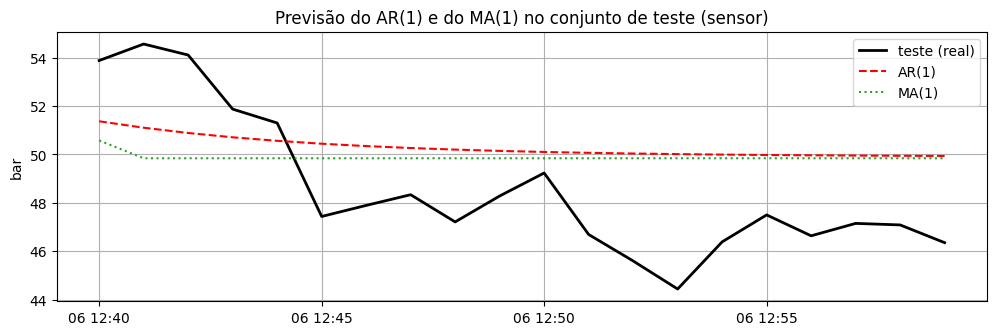

In [ ]:
plt.plot(teste_s.index, teste_s.values, color='black', linewidth=2, label='teste (real)')
plt.plot(previsoes_s.index, previsoes_s['AR(1)'], color='red', linestyle='--', label='AR(1)')
plt.plot(previsoes_s.index, previsoes_s['MA(1)'], color='tab:green', linestyle=':', label='MA(1)')
plt.title('Previsão do AR(1) e do MA(1) no conjunto de teste (sensor)')
plt.ylabel('bar')
plt.legend()
plt.show()

**Conclusão:** os dois modelos erram menos que o Naive nos 20 minutos de teste, e ficam muito próximos um do outro: a série do sensor depende dos valores passados (parte AR) e dos erros passados (parte MA), e cada modelo sozinho capta só uma das partes. O ARMA, da próxima seção, junta as duas.

## 📌 4 - Modelo ARMA

### 4.1 - Ajuste do ARMA(1,1)

O **ARMA** combina os dois modelos: a **parte AR** (valores passados) e a **parte MA** (erros passados):

$$x_t = \underbrace{c + \phi \, x_{t-1}}_{\text{parte AR}} + \underbrace{\theta \, \varepsilon_{t-1}}_{\text{parte MA}} + \underbrace{\varepsilon_t}_{\text{erro}}$$

Há uma **única sequência de erros**, a do próprio ARMA: o erro de agora, $\varepsilon_t$, vira o erro anterior, $\varepsilon_{t-1}$, no instante seguinte. Vamos ajustar o ARMA(1,1) ao treino da fábrica e ver as duas partes em ação.

O ARMA(1,1) é `order=(1, 0, 1)`, e o código estima o $\phi$ e o $\theta$ juntos. Ajustando ao **treino** da fábrica:

In [ ]:
# Parâmetros do modelo ARIMA(p, d, q)
p = 1  # AutoRegressivo (AR): quantidade de valores anteriores utilizados
d = 0  # Diferenciação (I): utilizada no ARIMA (assunto da próxima aula)
q = 1  # Média Móvel (MA): quantidade de erros anteriores utilizados

# Com (1, 0, 1), temos um modelo ARMA(1,1)
ajuste_arma = ARIMA(treino, order=(p, d, q), trend='c').fit()

Os nomes do resultado ligam aos símbolos da fórmula $x_t = c + \phi \, x_{t-1} + \theta \, \varepsilon_{t-1} + \varepsilon_t$: `const` é o $\mu$ (a média da série, e não o $c$), `ar.L1` é o $\phi$ (a parte AR) e `ma.L1` é o $\theta$ (a parte MA). Ligando cada símbolo ao seu valor:

In [ ]:
print('mi (const):', round(ajuste_arma.params['const'], 3))
print('phi (ar.L1):', round(ajuste_arma.params['ar.L1'], 3))
print('theta (ma.L1):', round(ajuste_arma.params['ma.L1'], 3))

mi (const): 115.595
phi (ar.L1): 0.885
theta (ma.L1): -0.083


Com os parâmetros estimados, a previsão da hora seguinte soma a **parte AR** e a **parte MA**. O $c$ da fórmula é $\mu \, (1 - \phi)$, o valor anterior é a última hora do treino, e o erro anterior é o último resíduo do modelo (`.resid`):

In [ ]:
mi_arma = ajuste_arma.params['const']
phi_arma = ajuste_arma.params['ar.L1']
theta_arma = ajuste_arma.params['ma.L1']
c_arma = mi_arma * (1 - phi_arma)

x_anterior = treino.iloc[-1]
erro_anterior_arma = ajuste_arma.resid.iloc[-1]

In [ ]:
parte_ar = c_arma + phi_arma * x_anterior
parte_ma = theta_arma * erro_anterior_arma
proxima = parte_ar + parte_ma

In [ ]:
print('Parte AR:', round(parte_ar, 2), '| parte MA:', round(parte_ma, 2), '| previsão da próxima hora:', round(proxima, 2))

Parte AR: 105.16 | parte MA: 0.58 | previsão da próxima hora: 105.73


O `.forecast(steps=1)` do próprio modelo dá o mesmo valor:

In [ ]:
print('Previsão com .forecast:', round(ajuste_arma.forecast(steps=1).iloc[0], 2))

Previsão com .forecast: 105.73


O ARMA(1,1) ajustado, para cada hora do treino, contra o consumo real nas últimas 60 horas:

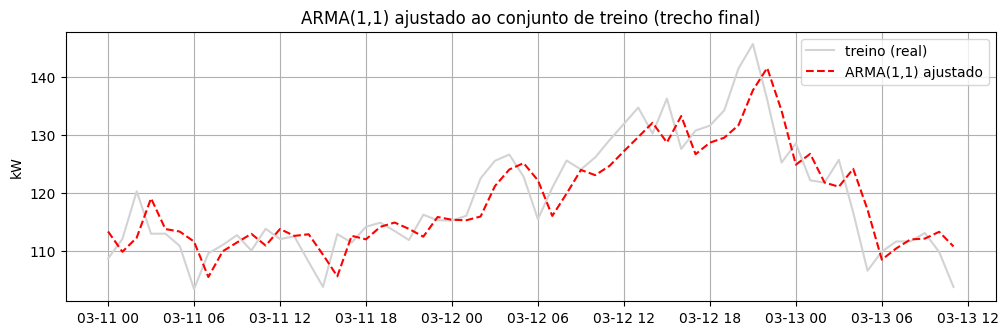

In [ ]:
plt.plot(treino.index[-60:], treino.values[-60:], color='lightgray', label='treino (real)')
plt.plot(ajuste_arma.fittedvalues.index[-60:], ajuste_arma.fittedvalues.values[-60:], color='red', linestyle='--', label='ARMA(1,1) ajustado')
plt.title('ARMA(1,1) ajustado ao conjunto de treino (trecho final)')
plt.ylabel('kW')
plt.legend()
plt.show()

### 4.2 - Previsão do ARMA(1,1)

No ARMA, a previsão combina as duas partes: no começo ela usa os valores e os erros recentes, e depois volta à média. Prevemos as 20 horas do teste, com o intervalo de confiança:

In [ ]:
previsao_arma = ajuste_arma.get_forecast(steps=h)
prev_arma = previsao_arma.predicted_mean

In [ ]:
intervalo_arma = previsao_arma.conf_int(alpha=0.05)

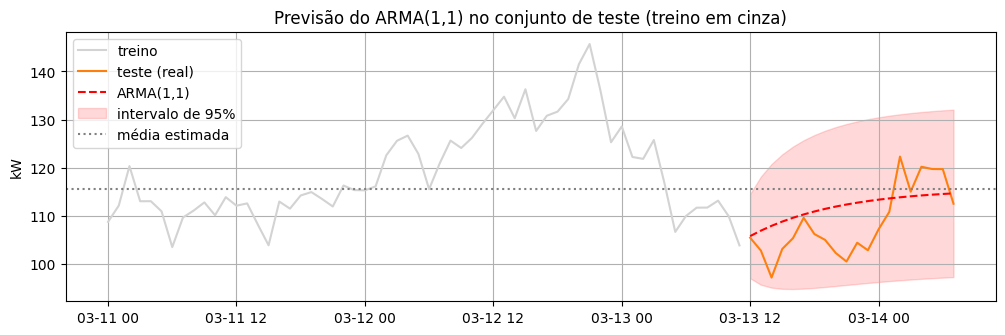

In [ ]:
plt.plot(treino.index[-60:], treino.values[-60:], color='lightgray', label='treino')
plt.plot(teste.index, teste.values, color='tab:orange', label='teste (real)')
plt.plot(prev_arma.index, prev_arma.values, color='red', linestyle='--', label='ARMA(1,1)')
plt.fill_between(intervalo_arma.index, intervalo_arma.iloc[:, 0], intervalo_arma.iloc[:, 1], color='red', alpha=0.15, label='intervalo de 95%')
plt.axhline(ajuste_arma.params['const'], color='gray', linestyle=':', label='média estimada')
plt.title('Previsão do ARMA(1,1) no conjunto de teste (treino em cinza)')
plt.ylabel('kW')
plt.legend()
plt.show()

Comparando o ARMA(1,1) e o Naive nas 20 horas do teste, pelo erro médio absoluto (MAE) e pela raiz do erro quadrático médio (RMSE):

In [ ]:
erros_prev_arma = pd.DataFrame({'ARMA(1,1)': teste - prev_arma, 'Naive': teste - naive})

In [ ]:
tabela_arma = pd.DataFrame({
    'MAE (kW)': erros_prev_arma.abs().mean(),
    'RMSE (kW)': np.sqrt((erros_prev_arma ** 2).mean()),
})

In [ ]:
for nome, linha in tabela_arma.sort_values('MAE (kW)').iterrows():
    print(nome, '| MAE (kW):', round(linha['MAE (kW)'], 2), '| RMSE (kW):', round(linha['RMSE (kW)'], 2))

ARMA(1,1) | MAE (kW): 5.71 | RMSE (kW): 6.6
Naive | MAE (kW): 6.21 | RMSE (kW): 8.6


**Conclusão:** o ARMA(1,1) erra menos que o Naive. Ele apresentou comportamento próximo ao do AR(1), com pequena contribuição estimada da componente MA (o $\theta$ estimado é pequeno).

## 📌 5 - Comparativo de modelos

Para comparar, os três modelos, já ajustados ao treino da fábrica, preveem o **mesmo período de teste** (as 20 horas). Juntamos o AR(1), o MA(1) e o ARMA(1,1) em um dicionário:

In [ ]:
ajustes_f = {
    'AR(1)': resultado_ar1,
    'MA(1)': ajuste_ma,
    'ARMA(1,1)': ajuste_arma,
}

Cada modelo prevê as 20 horas:

In [ ]:
previsoes_f = pd.DataFrame({nome: ajuste.forecast(steps=h) for nome, ajuste in ajustes_f.items()})

O Naive entra como baseline, repetindo o último valor do treino:

In [ ]:
previsoes_f['Naive'] = naive

In [ ]:
previsoes_f.head()

,AR(1),MA(1),"ARMA(1,1)",Naive
2024-03-13 12:00:00,105.326245,109.730339,105.734519,103.800188
2024-03-13 13:00:00,106.650232,115.808555,106.868621,103.800188
2024-03-13 14:00:00,107.798905,115.808555,107.872281,103.800188
2024-03-13 15:00:00,108.795478,115.808555,108.760501,103.800188
2024-03-13 16:00:00,109.660091,115.808555,109.546560,103.800188


O erro de cada coluna (`.rsub` subtrai cada previsão do valor real), e depois o MAE e o RMSE:

In [ ]:
erros_f = previsoes_f.rsub(teste, axis=0)

In [ ]:
tabela_f = pd.DataFrame({
    'MAE (kW)': erros_f.abs().mean(),
    'RMSE (kW)': np.sqrt((erros_f ** 2).mean()),
})

In [ ]:
for nome, linha in tabela_f.sort_values('MAE (kW)').iterrows():
    print(nome, '| MAE (kW):', round(linha['MAE (kW)'], 2), '| RMSE (kW):', round(linha['RMSE (kW)'], 2))

ARMA(1,1) | MAE (kW): 5.71 | RMSE (kW): 6.6
AR(1) | MAE (kW): 5.76 | RMSE (kW): 6.67
Naive | MAE (kW): 6.21 | RMSE (kW): 8.6
MA(1) | MAE (kW): 8.8 | RMSE (kW): 9.97


**Conclusão:** nas 20 horas de teste, o ARMA(1,1) e o AR(1) empatam, e os dois erram menos que o Naive. O MA(1) é o pior, pior até que o Naive: neste teste, a série da fábrica mostrou depender mais dos valores passados do que dos erros recentes. O ARMA(1,1) acompanhou o AR(1), com pequena contribuição estimada da parte MA.

## 🎯 Momento de praticar

Use o consumo da **planta B**, a segunda planta da empresa (uma medida por hora), para **prever as últimas 24 horas** e comparar os modelos.

O consumo industrial tem um ciclo que se repete por dia e por semana, e os modelos AR, MA e ARMA funcionam melhor sobre uma série sem esse ciclo. Por isso, em vez de prever o consumo direto, separamos duas partes: o **perfil típico da semana** (o consumo mediano de cada hora de cada dia da semana) e o **desvio** em relação ao perfil. Aplicamos os modelos ao desvio e, no final, **somamos o perfil de volta** para recuperar a previsão em kW.

Os passos:

1. Carregue o dataset e recrie o consumo **horário**: remova os timestamps repetidos, complete as horas sem medida com `.interpolate()` e mostre o resultado
2. Reserve as **últimas 24 horas** para teste, calcule o **perfil típico** da semana (mediana por dia da semana e hora) **só com o treino** e o **desvio** em relação a ele, e plote uma semana do desvio, a de 04/03 a 10/03
3. Ajuste **AR(1), AR(2), MA(1) e ARMA(1,1)** ao desvio do treino
4. Preveja as 24 horas, some o perfil e calcule o **MAE** de cada modelo, do perfil sozinho e do Naive
5. Plote o real com a melhor previsão

> **Dica:** a planta B tem alguns timestamps repetidos e valores ausentes (a Aula 1 mostrou como tratar). O `.index.duplicated()` marca os repetidos, e o `.asfreq('h')` cria as horas faltantes como `NaN`. O perfil sai **só do treino**, com `.groupby([horario.index.dayofweek, horario.index.hour]).median()`, e o `.reindex` com o `pd.MultiIndex.from_arrays([horario.index.dayofweek, horario.index.hour])` dá a cada instante o perfil do seu dia da semana e da sua hora.

Para carregar e recriar a série, use:

```python
df_b = pd.read_csv(
    PATH + 'datasets/consumo_energia_planta_b.csv',
    parse_dates=['timestamp'],
    index_col='timestamp',
)
potencia_b = df_b['potencia_kw']
potencia_b = potencia_b[~potencia_b.index.duplicated()]
horario_b = potencia_b.asfreq('h').interpolate()
```

**Passo 1:** carregue o dataset e recrie o consumo horário da planta B.

In [ ]:
df_b = pd.read_csv(
    PATH + 'datasets/consumo_energia_planta_b.csv',
    parse_dates=['timestamp'],
    index_col='timestamp',
)

In [ ]:
df_b.head()

,potencia_kw
timestamp,
2024-01-01 00:00:00,256.6
2024-01-01 01:00:00,259.6
2024-01-01 02:00:00,253.8
2024-01-01 03:00:00,247.4
2024-01-01 04:00:00,251.9


In [ ]:
potencia_b = df_b['potencia_kw']

In [ ]:
print('Timestamps repetidos:', int(potencia_b.index.duplicated().sum()))
print('Valores ausentes:', int(potencia_b.isna().sum()))

Timestamps repetidos: 12
Valores ausentes: 19


Removendo os timestamps repetidos:

In [ ]:
potencia_b = potencia_b[~potencia_b.index.duplicated()]

Completando as horas sem medida: o `.asfreq('h')` cria as horas faltantes como `NaN`, e o `.interpolate()` preenche:

In [ ]:
horario_b = potencia_b.asfreq('h').interpolate()

In [ ]:
horario_b.head()

,potencia_kw
timestamp,
2024-01-01 00:00:00,256.6
2024-01-01 01:00:00,259.6
2024-01-01 02:00:00,253.8
2024-01-01 03:00:00,247.4
2024-01-01 04:00:00,251.9


In [ ]:
print('Número de horas:', len(horario_b), '| valores ausentes depois do tratamento:', int(horario_b.isna().sum()))

Número de horas: 8784 | valores ausentes depois do tratamento: 0


**Passo 2:** reserve as últimas 24 horas, calcule o perfil típico só com o treino e o desvio, e plote a semana de 04/03 a 10/03.

In [ ]:
horario_b_treino = horario_b.iloc[:-24]

In [ ]:
perfil_tipico_b = horario_b_treino.groupby([horario_b_treino.index.dayofweek, horario_b_treino.index.hour]).median().rename_axis(['dia da semana', 'hora'])

In [ ]:
perfil_tipico_b.head()

dia da semana  hora
0              0       459.1
               1       468.9
               2       471.7
               3       464.0
               4       460.9
Name: potencia_kw, dtype: float64

In [ ]:
chaves_b = pd.MultiIndex.from_arrays([horario_b.index.dayofweek, horario_b.index.hour])
perfil_b = pd.Series(perfil_tipico_b.reindex(chaves_b).values, index=horario_b.index)

In [ ]:
desvio_b = horario_b - perfil_b

In [ ]:
desvio_b.head()

,0
timestamp,
2024-01-01 00:00:00,-202.5
2024-01-01 01:00:00,-209.3
2024-01-01 02:00:00,-217.9
2024-01-01 03:00:00,-216.6
2024-01-01 04:00:00,-209.0


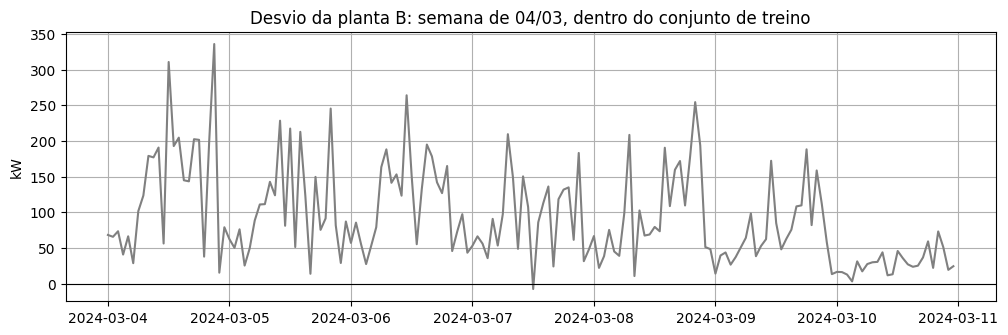

In [ ]:
plt.plot(desvio_b['2024-03-04':'2024-03-10'], color='gray')
plt.axhline(0, color='black', linewidth=0.8)
plt.title('Desvio da planta B: semana de 04/03, dentro do conjunto de treino')
plt.ylabel('kW')
plt.show()

**Passo 3:** ajuste os quatro modelos ao desvio do treino.

In [ ]:
treino_b = desvio_b.iloc[:-24]

In [ ]:
ajustes_b = {
    'AR(1)': AutoReg(treino_b, lags=1, trend='c').fit(),
    'AR(2)': AutoReg(treino_b, lags=2, trend='c').fit(),
    'MA(1)': ARIMA(treino_b, order=(0, 0, 1), trend='c').fit(),
    'ARMA(1,1)': ARIMA(treino_b, order=(1, 0, 1), trend='c').fit(),
}

In [ ]:
for nome, ajuste in ajustes_b.items():
    print(nome, '| parâmetros:', ajuste.params.drop('sigma2', errors='ignore').round(2).to_dict())

AR(1) | parâmetros: {'const': -0.99, 'y.L1': 0.89}
AR(2) | parâmetros: {'const': -0.68, 'y.L1': 0.63, 'y.L2': 0.29}
MA(1) | parâmetros: {'const': -9.1, 'ma.L1': 0.67}
ARMA(1,1) | parâmetros: {'const': -9.1, 'ar.L1': 0.95, 'ma.L1': -0.34}


**Passo 4:** preveja as 24 horas, some o perfil e calcule o MAE.

In [ ]:
perfil_teste_b = perfil_b.iloc[-24:]
real_b = horario_b.iloc[-24:]

In [ ]:
pd.DataFrame({'real': real_b, 'perfil': perfil_teste_b}).head()

,real,perfil
timestamp,,
2024-12-31 00:00:00,524.3,463.50
2024-12-31 01:00:00,501.6,465.50
2024-12-31 02:00:00,557.3,471.00
2024-12-31 03:00:00,472.8,467.55
2024-12-31 04:00:00,518.1,472.05


In [ ]:
previsoes_b = pd.DataFrame({
    nome: ajuste.forecast(steps=24) + perfil_teste_b
    for nome, ajuste in ajustes_b.items()
})

In [ ]:
previsoes_b['Perfil (desvio = 0)'] = perfil_teste_b
previsoes_b['Naive'] = horario_b.iloc[-25]

In [ ]:
previsoes_b.round(0).head()

,AR(1),AR(2),MA(1),"ARMA(1,1)",Perfil (desvio = 0),Naive
2024-12-31 00:00:00,504.0,521.0,469.0,524.0,464.0,552.0
2024-12-31 01:00:00,501.0,514.0,456.0,523.0,466.0,552.0
2024-12-31 02:00:00,501.0,518.0,462.0,525.0,471.0,552.0
2024-12-31 03:00:00,493.0,511.0,458.0,519.0,468.0,552.0
2024-12-31 04:00:00,494.0,512.0,463.0,521.0,472.0,552.0


In [ ]:
erros_b = previsoes_b.rsub(real_b, axis=0)

In [ ]:
tabela_b = pd.DataFrame({
    'MAE (kW)': erros_b.abs().mean(),
    'RMSE (kW)': np.sqrt((erros_b ** 2).mean()),
})

In [ ]:
for nome, linha in tabela_b.sort_values('MAE (kW)').iterrows():
    print(nome, '| MAE (kW):', round(linha['MAE (kW)'], 2), '| RMSE (kW):', round(linha['RMSE (kW)'], 2))

ARMA(1,1) | MAE (kW): 62.9 | RMSE (kW): 85.45
AR(2) | MAE (kW): 68.34 | RMSE (kW): 91.43
AR(1) | MAE (kW): 82.28 | RMSE (kW): 103.1
Perfil (desvio = 0) | MAE (kW): 89.08 | RMSE (kW): 105.6
MA(1) | MAE (kW): 97.59 | RMSE (kW): 113.05
Naive | MAE (kW): 634.84 | RMSE (kW): 761.31


**Passo 5:** plote o real com a melhor previsão.

In [ ]:
melhor = tabela_b['MAE (kW)'].idxmin()

In [ ]:
melhor

'ARMA(1,1)'

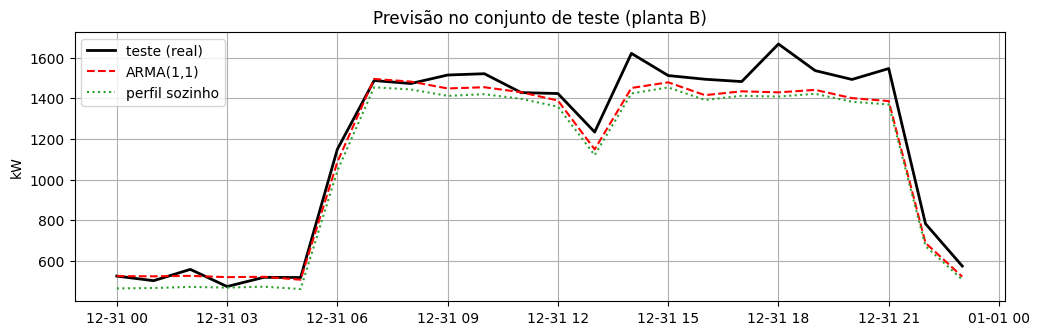

In [ ]:
plt.plot(real_b.index, real_b.values, color='black', linewidth=2, label='teste (real)')
plt.plot(previsoes_b.index, previsoes_b[melhor], color='red', linestyle='--', label=melhor)
plt.plot(previsoes_b.index, previsoes_b['Perfil (desvio = 0)'], color='tab:green', linestyle=':', label='perfil sozinho')
plt.title('Previsão no conjunto de teste (planta B)')
plt.ylabel('kW')
plt.legend()
plt.show()

**Conclusão:** na planta B, o desvio do perfil tem memória, e o ARMA(1,1) é o que erra menos nas 24 horas finais, seguido do AR(2) e do AR(1), todos melhores que o perfil sozinho e que o Naive. O MA(1) é o pior, pior que o perfil sozinho: o desvio depende do passado do próprio consumo, e não só de erros recentes.

## 📌 Conclusão

* **Dependência:** o valor de agora se parece com os anteriores. A defasagem (lag) mede isso, e a reta de regressão de $x_t$ sobre $x_{t-1}$ é o AR(1)
* **AR:** regressão da série sobre ela mesma defasada. O $\phi$ é a inclinação (o peso do passado) e o $p$ é quantos lags entram
* **MA:** o valor depende dos erros passados ($\theta$), com memória de $q$ períodos. O erro anterior é o erro de previsão do próprio modelo
* **ARMA:** combina a parte AR (valores passados) e a parte MA (erros passados), com uma única sequência de erros. O código estima $\phi$ e $\theta$ (`AutoReg` para o AR, `ARIMA` com `order=(p, 0, q)` para o MA e o ARMA)
* **Previsão:** a do AR volta à média e a do MA vira a média depois de $q$ passos; a incerteza cresce com o horizonte. Reserve um período final para teste
* **Comparativo de modelos:** compare os modelos no mesmo período reservado, com MAE e RMSE, sempre contra um baseline (Naive, perfil)
* **Próxima aula:** a **Aula 4** traz a estacionariedade (e o teste ADF), a diferenciação e o ARIMA, para séries com tendência